In [1]:
import zipfile
from pathlib import Path
import os

zip_path = "/content/tugas-hands-on-3.zip"
extract_path = "/content"

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

os.chdir("/content/tugas-hands-on-3")

print("Folder kerja:", os.getcwd())
print("Isi folder:", os.listdir("."))
print("Dataset tersedia:", Path("data/case2_customer_churn.csv").exists())


Folder kerja: /content/tugas-hands-on-3
Isi folder: ['data', 'output', 'laporan_kualitas.csv', 'README.md', 'notebook.ipynb']
Dataset tersedia: True


# Hands-On 3: Pandas Lanjutan — Customer Churn Analysis

**Mata kuliah:** Artificial Intelligence  
**Kasus:** Customer Churn Analysis (Telekomunikasi)  
**Tujuan:** audit kualitas data, pembersihan yang dapat diulang, analisis eksploratif, dan persiapan data untuk klasifikasi tanpa data leakage.

Dataset berisi 5.000 baris dan 12 kolom. Target klasifikasi adalah `status_pelanggan` dengan kelas `Aktif` dan `Churn`.

> Catatan metodologis: pembersihan untuk menghasilkan CSV bersih didokumentasikan terpisah. Pada jalur pemodelan, data mentah yang sudah dibuang duplikatnya digunakan dan imputasi, scaling, serta encoding dilakukan di dalam `Pipeline` setelah train-test split agar parameter preprocessing hanya dipelajari dari data train.

## 1. Import library dan muat data

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

RANDOM_STATE = 2026
DATA_PATH = Path("data/case2_customer_churn.csv")
OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)

df_mentah = pd.read_csv(DATA_PATH)
print("Ukuran dataset:", df_mentah.shape)
display(df_mentah.head())

Ukuran dataset: (5000, 12)


,customer_id,lama_berlangganan_bulan,jenis_kontrak,tagihan_bulanan_idr,total_tagihan_idr,layanan_internet,jumlah_layanan_aktif,dukungan_teknis,jumlah_komplain,hari_sejak_interaksi_terakhir,metode_pembayaran,status_pelanggan
0,TEL000001,41.0,Dua Tahun,140611.0,5860742.0,DSL,8.0,Tidak,11.0,331.0,Transfer Bank,Aktif
1,TEL000002,5.0,Tahunan,363720.0,1742224.0,Tidak Ada,7.0,Ya,12.0,156.0,Autodebet,Aktif
2,TEL000003,56.0,Bulanan,208727.0,11685438.0,DSL,6.0,Tidak,9.0,105.0,Transfer Bank,Churn
3,TEL000004,NaN,Dua Tahun,135607.0,5599065.0,Fiber Optik,2.0,Ya,12.0,100.0,Kartu Kredit,Churn
4,TEL000005,7.0,Bulanan,71099.0,427199.0,Tidak Ada,1.0,Tidak,1.0,19.0,QRIS,Churn


In [3]:
df_mentah.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   customer_id                    5000 non-null   object 
 1   lama_berlangganan_bulan        4900 non-null   float64
 2   jenis_kontrak                  4853 non-null   object 
 3   tagihan_bulanan_idr            4857 non-null   float64
 4   total_tagihan_idr              4763 non-null   float64
 5   layanan_internet               4844 non-null   object 
 6   jumlah_layanan_aktif           4819 non-null   float64
 7   dukungan_teknis                4852 non-null   object 
 8   jumlah_komplain                4836 non-null   float64
 9   hari_sejak_interaksi_terakhir  4797 non-null   float64
 10  metode_pembayaran              4841 non-null   object 
 11  status_pelanggan               5000 non-null   object 
dtypes: float64(6), object(6)
memory usage: 468.9+ KB

In [4]:
display(df_mentah.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,5000,5000,TEL005000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
lama_berlangganan_bulan,4900.0,NaN,NaN,NaN,36.624082,21.056159,1.0,18.0,36.0,55.0,72.0
jenis_kontrak,4853,12,Dua Tahun,1623,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tagihan_bulanan_idr,4857.0,NaN,NaN,NaN,273390.50525,130685.216371,50245.0,160098.0,272473.0,388440.0,499966.0
total_tagihan_idr,4763.0,NaN,NaN,NaN,9962092.867311,7951488.773458,0.0,3503040.0,7873608.0,14646495.5,35615528.0
layanan_internet,4844,3,Tidak Ada,1637,NaN,NaN,NaN,NaN,NaN,NaN,NaN
jumlah_layanan_aktif,4819.0,NaN,NaN,NaN,4.52874,2.282951,1.0,3.0,5.0,7.0,8.0
dukungan_teknis,4852,2,Ya,2489,NaN,NaN,NaN,NaN,NaN,NaN,NaN
jumlah_komplain,4836.0,NaN,NaN,NaN,7.482837,4.672071,0.0,3.0,8.0,12.0,15.0
hari_sejak_interaksi_terakhir,4797.0,NaN,NaN,NaN,182.542631,105.117812,0.0,93.0,183.0,272.0,365.0


## 2. Audit kualitas data

Audit dilakukan terhadap jumlah baris, duplikat berdasarkan `customer_id`, missing value, dan outlier numerik menggunakan aturan IQR di dalam kelompok `status_pelanggan`. Nilai outlier tidak langsung dianggap salah; untuk dataset ini, nilai di luar batas IQR ditangani dengan clipping pada batas bawah/atas IQR per kelompok.

In [5]:
kolom_num = [
    "lama_berlangganan_bulan",
    "tagihan_bulanan_idr",
    "total_tagihan_idr",
    "jumlah_layanan_aktif",
    "jumlah_komplain",
    "hari_sejak_interaksi_terakhir",
]
kolom_grup = "status_pelanggan"
kunci = ["customer_id"]

def cek_kualitas(d, kolom_num=kolom_num, kolom_grup=kolom_grup, kunci=kunci):
    # Hitung outlier per kolom numerik dengan batas IQR yang dihitung per grup.
    n_outlier = 0
    for kolom in kolom_num:
        g = d.groupby(kolom_grup, observed=True)[kolom]
        q1 = g.transform(lambda s: s.quantile(0.25))
        q3 = g.transform(lambda s: s.quantile(0.75))
        iqr = q3 - q1
        mask = (d[kolom] < q1 - 1.5 * iqr) | (d[kolom] > q3 + 1.5 * iqr)
        n_outlier += int(mask.sum())
    return pd.Series({
        "n_baris": len(d),
        "n_duplikat_customer_id": int(d.duplicated(subset=kunci).sum()),
        "n_missing": int(d.isna().sum().sum()),
        "n_outlier_total": n_outlier,
    })

display(cek_kualitas(df_mentah))
print("Missing value per kolom:")
display(df_mentah.isna().sum().sort_values(ascending=False).to_frame("n_missing"))
print("Duplikat berdasarkan customer_id:", df_mentah.duplicated(subset=["customer_id"]).sum())

,0
n_baris,5000
n_duplikat_customer_id,0
n_missing,1638
n_outlier_total,55


Missing value per kolom:


,n_missing
total_tagihan_idr,237
hari_sejak_interaksi_terakhir,203
jumlah_layanan_aktif,181
jumlah_komplain,164
metode_pembayaran,159
layanan_internet,156
dukungan_teknis,148
jenis_kontrak,147
tagihan_bulanan_idr,143
lama_berlangganan_bulan,100


Duplikat berdasarkan customer_id: 0


## 3. Pembersihan data

Urutan pembersihan mengikuti instruksi tugas: **duplikat → missing value → outlier → tipe data**.

- Duplikat dihapus berdasarkan `customer_id`, karena satu ID seharusnya merepresentasikan satu pelanggan.
- Ejaan kategori kontrak distandardisasi (`bulanan`, `tahunan`, `dua tahun`, termasuk variasi dengan karakter `@`) supaya kategori yang sama tidak terhitung berbeda.
- Missing numerik diisi median kolom; kategori diisi modus kolom. Median/modus digunakan karena tahan terhadap nilai ekstrem dan menjaga jumlah baris.
- Outlier numerik di-clip menggunakan batas IQR per `status_pelanggan`. Ini mengurangi pengaruh nilai ekstrem tanpa menghapus baris.
- Kolom jumlah dan durasi dibulatkan menjadi bilangan bulat; kolom biaya tetap numerik dan kolom kategori diubah menjadi tipe `category`.

In [6]:
df_bersih = df_mentah.copy()

# 1) Hapus duplikat berdasarkan kunci pelanggan.
df_bersih = df_bersih.drop_duplicates(subset=kunci, keep="first").copy()

# Standardisasi teks kategori kontrak sebelum imputasi kategori.
df_bersih["jenis_kontrak"] = (
    df_bersih["jenis_kontrak"].astype("string").str.strip().str.lower()
    .str.replace("@", "a", regex=False)
)
df_bersih["jenis_kontrak"] = df_bersih["jenis_kontrak"].replace({
    "bulanan": "Bulanan",
    "tahunan": "Tahunan",
    "dua tahun": "Dua Tahun",
})

# 2) Tangani missing value: median untuk numerik, modus untuk kategori.
kolom_kategorik = ["jenis_kontrak", "layanan_internet", "dukungan_teknis", "metode_pembayaran"]
for kolom in kolom_num:
    df_bersih[kolom] = df_bersih[kolom].fillna(df_bersih[kolom].median())

for kolom in kolom_kategorik:
    modus = df_bersih[kolom].mode(dropna=True)
    nilai_pengganti = modus.iloc[0] if not modus.empty else "Tidak diketahui"
    df_bersih[kolom] = df_bersih[kolom].fillna(nilai_pengganti)

# 3) Tangani outlier: clipping batas IQR per status pelanggan.
ringkasan_outlier = {}
for kolom in kolom_num:
    grup = df_bersih.groupby(kolom_grup, observed=True)[kolom]
    q1 = grup.transform(lambda s: s.quantile(0.25))
    q3 = grup.transform(lambda s: s.quantile(0.75))
    iqr = q3 - q1
    batas_bawah = q1 - 1.5 * iqr
    batas_atas = q3 + 1.5 * iqr
    mask_outlier = (df_bersih[kolom] < batas_bawah) | (df_bersih[kolom] > batas_atas)
    ringkasan_outlier[kolom] = int(mask_outlier.sum())
    df_bersih[kolom] = df_bersih[kolom].clip(lower=batas_bawah, upper=batas_atas)

print("Jumlah outlier sebelum clipping per kolom:")
display(pd.Series(ringkasan_outlier, name="n_outlier_sebelum_clipping").to_frame())

# 4) Perbaiki tipe data.
df_bersih["customer_id"] = df_bersih["customer_id"].astype("string")
for kolom in ["lama_berlangganan_bulan", "jumlah_layanan_aktif", "jumlah_komplain", "hari_sejak_interaksi_terakhir"]:
    df_bersih[kolom] = df_bersih[kolom].round().astype("int64")
for kolom in ["tagihan_bulanan_idr", "total_tagihan_idr"]:
    df_bersih[kolom] = df_bersih[kolom].round(2)
for kolom in kolom_kategorik + ["status_pelanggan"]:
    df_bersih[kolom] = df_bersih[kolom].astype("category")

display(df_bersih.head())
print("Ukuran setelah pembersihan:", df_bersih.shape)

Jumlah outlier sebelum clipping per kolom:


,n_outlier_sebelum_clipping
lama_berlangganan_bulan,0
tagihan_bulanan_idr,0
total_tagihan_idr,100
jumlah_layanan_aktif,0
jumlah_komplain,0
hari_sejak_interaksi_terakhir,0


,customer_id,lama_berlangganan_bulan,jenis_kontrak,tagihan_bulanan_idr,total_tagihan_idr,layanan_internet,jumlah_layanan_aktif,dukungan_teknis,jumlah_komplain,hari_sejak_interaksi_terakhir,metode_pembayaran,status_pelanggan
0,TEL000001,41,Dua Tahun,140611.0,5860742.0,DSL,8,Tidak,11,331,Transfer Bank,Aktif
1,TEL000002,5,Tahunan,363720.0,1742224.0,Tidak Ada,7,Ya,12,156,Autodebet,Aktif
2,TEL000003,56,Bulanan,208727.0,11685438.0,DSL,6,Tidak,9,105,Transfer Bank,Churn
3,TEL000004,36,Dua Tahun,135607.0,5599065.0,Fiber Optik,2,Ya,12,100,Kartu Kredit,Churn
4,TEL000005,7,Bulanan,71099.0,427199.0,Tidak Ada,1,Tidak,1,19,QRIS,Churn


Ukuran setelah pembersihan: (5000, 12)


## 4. Bandingkan kualitas sebelum dan sesudah

In [7]:
laporan_kualitas = pd.DataFrame({
    "sebelum": cek_kualitas(df_mentah),
    "sesudah": cek_kualitas(df_bersih),
})
display(laporan_kualitas)
laporan_kualitas.to_csv("laporan_kualitas.csv", index=True, index_label="metrik")

,sebelum,sesudah
n_baris,5000,5000
n_duplikat_customer_id,0,0
n_missing,1638,0
n_outlier_total,55,0


**Interpretasi hasil audit:** data berisi 5.000 baris dan tidak memiliki duplikat `customer_id`. Sebelum pembersihan terdapat 1.638 sel missing dan 55 nilai outlier berdasarkan IQR per kelompok. Setelah pembersihan, missing value menjadi 0 dan tidak ada outlier yang melewati batas IQR yang dihitung ulang. Jumlah baris tetap 5.000 karena missing value ditangani dengan imputasi dan outlier ditangani dengan clipping, bukan menghapus baris.

## 5. Analisis eksploratif

Tidak ada kolom tanggal transaksi pada dataset ini, sehingga analisis time series tidak diterapkan. RFM juga tidak sesuai karena data tidak memiliki catatan transaksi individual dan frekuensi transaksi pelanggan. Analisis difokuskan pada tingkat churn berdasarkan kontrak, komplain, dan layanan.

,jumlah
status_pelanggan,
Aktif,2819
Churn,2181


,persen
status_pelanggan,
Aktif,56.38
Churn,43.62


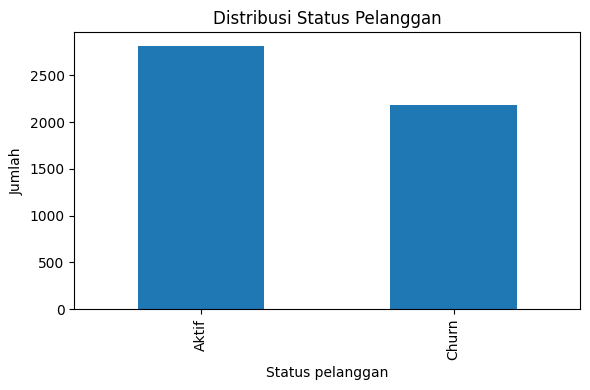

In [8]:
# Distribusi target
display(df_bersih["status_pelanggan"].value_counts().to_frame("jumlah"))
display((df_bersih["status_pelanggan"].value_counts(normalize=True) * 100).round(2).to_frame("persen"))

plt.figure(figsize=(6, 4))
df_bersih["status_pelanggan"].astype(str).value_counts().plot(kind="bar")
plt.title("Distribusi Status Pelanggan")
plt.xlabel("Status pelanggan")
plt.ylabel("Jumlah")
plt.tight_layout()
plt.show()

In [9]:
def ringkasan_churn(kolom):
    hasil = df_bersih.groupby(kolom, observed=True).agg(
        jumlah=("status_pelanggan", "size"),
        churn=("status_pelanggan", lambda s: (s == "Churn").sum()),
    )
    hasil["persen_churn"] = (hasil["churn"] / hasil["jumlah"] * 100).round(2)
    return hasil.sort_values("persen_churn", ascending=False)

display(ringkasan_churn("jenis_kontrak"))
display(ringkasan_churn("dukungan_teknis"))
display(ringkasan_churn("metode_pembayaran"))

,jumlah,churn,persen_churn
jenis_kontrak,,,
Bulanan,1793,1047,58.39
Tahunan,1563,620,39.67
Dua Tahun,1644,514,31.27


,jumlah,churn,persen_churn
dukungan_teknis,,,
Tidak,2363,1048,44.35
Ya,2637,1133,42.97


,jumlah,churn,persen_churn
metode_pembayaran,,,
Kartu Kredit,1187,541,45.58
Transfer Bank,1231,540,43.87
QRIS,1421,608,42.79
Autodebet,1161,492,42.38


,jumlah,churn,persen_churn
kelompok_komplain,,,
0–3,1237,296,23.93
4–7,1178,436,37.01
8–11,1351,746,55.22
12–15,1234,703,56.97


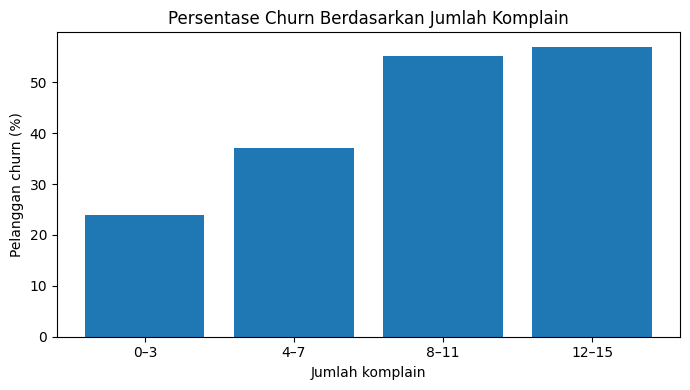

In [10]:
# Analisis jumlah komplain dengan kelompok yang mudah dibaca.
df_bersih["kelompok_komplain"] = pd.cut(
    df_bersih["jumlah_komplain"],
    bins=[-1, 3, 7, 11, 15],
    labels=["0–3", "4–7", "8–11", "12–15"],
)
analisis_komplain = df_bersih.groupby("kelompok_komplain", observed=True).agg(
    jumlah=("status_pelanggan", "size"),
    churn=("status_pelanggan", lambda s: (s == "Churn").sum()),
)
analisis_komplain["persen_churn"] = (analisis_komplain["churn"] / analisis_komplain["jumlah"] * 100).round(2)
display(analisis_komplain)

plt.figure(figsize=(7, 4))
plt.bar(analisis_komplain.index.astype(str), analisis_komplain["persen_churn"].to_numpy())
plt.title("Persentase Churn Berdasarkan Jumlah Komplain")
plt.xlabel("Jumlah komplain")
plt.ylabel("Pelanggan churn (%)")
plt.tight_layout()
plt.show()

### Tiga temuan yang dapat ditindaklanjuti

1. **Pelanggan dengan kontrak bulanan memiliki tingkat churn tertinggi.** Tingkat churn kontrak bulanan sekitar 58,39%, dibandingkan kontrak tahunan 39,67% dan dua tahun 31,27%. Tim retensi dapat menguji program loyalitas atau penawaran perpanjangan kontrak bagi pelanggan bulanan.
2. **Jumlah komplain berkaitan dengan tingkat churn yang lebih tinggi.** Kelompok dengan 0–3 komplain memiliki churn sekitar 23,93%, sedangkan kelompok 8–11 dan 12–15 komplain masing-masing sekitar 55,22% dan 56,97%. Perusahaan dapat memprioritaskan penyelesaian komplain berulang dan melakukan tindak lanjut setelah masalah diselesaikan.
3. **Churn keseluruhan cukup besar.** Sekitar 43,62% pelanggan berstatus churn pada dataset ini. Tim bisnis dapat menggunakan model klasifikasi sebagai alat bantu untuk menyaring pelanggan berisiko, lalu memvalidasi hasilnya sebelum menjalankan intervensi retensi.

Temuan di atas menunjukkan hubungan dalam data, bukan bukti bahwa suatu faktor pasti menyebabkan churn.

## 6. Simpan CSV bersih dan kamus data

In [11]:
# Kolom analisis sementara tidak disertakan dalam CSV final.
df_final = df_bersih.drop(columns=["kelompok_komplain"], errors="ignore").copy()
df_final.to_csv(OUTPUT_DIR / "data_bersih.csv", index=False)

keterangan_kolom = {
    "customer_id": "ID unik pelanggan; tidak digunakan sebagai fitur model",
    "lama_berlangganan_bulan": "Lama pelanggan berlangganan dalam bulan",
    "jenis_kontrak": "Jenis kontrak berlangganan",
    "tagihan_bulanan_idr": "Tagihan bulanan dalam Rupiah",
    "total_tagihan_idr": "Total tagihan dalam Rupiah",
    "layanan_internet": "Jenis layanan internet",
    "jumlah_layanan_aktif": "Jumlah layanan aktif",
    "dukungan_teknis": "Status penggunaan dukungan teknis",
    "jumlah_komplain": "Jumlah komplain pelanggan",
    "hari_sejak_interaksi_terakhir": "Hari sejak interaksi terakhir",
    "metode_pembayaran": "Metode pembayaran",
    "status_pelanggan": "Target klasifikasi: Aktif atau Churn",
}
kamus_data = pd.DataFrame({
    "kolom": df_final.columns,
    "tipe_data": [str(df_final[c].dtype) for c in df_final.columns],
    "n_missing": [int(df_final[c].isna().sum()) for c in df_final.columns],
    "n_unik": [int(df_final[c].nunique(dropna=True)) for c in df_final.columns],
    "keterangan": [keterangan_kolom.get(c, "") for c in df_final.columns],
})
kamus_data.to_csv(OUTPUT_DIR / "kamus_data.csv", index=False)
display(kamus_data)

,kolom,tipe_data,n_missing,n_unik,keterangan
0,customer_id,string,0,5000,ID unik pelanggan; tidak digunakan sebagai fit...
1,lama_berlangganan_bulan,int64,0,72,Lama pelanggan berlangganan dalam bulan
2,jenis_kontrak,category,0,3,Jenis kontrak berlangganan
3,tagihan_bulanan_idr,float64,0,4822,Tagihan bulanan dalam Rupiah
4,total_tagihan_idr,float64,0,4665,Total tagihan dalam Rupiah
5,layanan_internet,category,0,3,Jenis layanan internet
6,jumlah_layanan_aktif,int64,0,8,Jumlah layanan aktif
7,dukungan_teknis,category,0,2,Status penggunaan dukungan teknis
8,jumlah_komplain,int64,0,16,Jumlah komplain pelanggan
9,hari_sejak_interaksi_terakhir,int64,0,366,Hari sejak interaksi terakhir


## 7. Persiapan model tanpa data leakage

Untuk tahap pemodelan, preprocessing tidak menggunakan `df_final` yang sudah diimputasi dari keseluruhan dataset. Kita mulai lagi dari data mentah, membuang duplikat, memisahkan target, lalu melakukan `train_test_split` dengan `stratify=y`. Imputasi, scaling, dan encoding di-fit hanya pada data train melalui `Pipeline` dan `ColumnTransformer`.

In [12]:
# Data untuk model berasal dari data mentah; jangan gunakan hasil imputasi seluruh dataset.
df_model = df_mentah.drop_duplicates(subset=["customer_id"], keep="first").copy()

# Standardisasi kategori deterministik (bukan statistik yang dipelajari dari data).
df_model["jenis_kontrak"] = (
    df_model["jenis_kontrak"].astype("string").str.strip().str.lower()
    .str.replace("@", "a", regex=False)
)
df_model["jenis_kontrak"] = df_model["jenis_kontrak"].replace({
    "bulanan": "Bulanan",
    "tahunan": "Tahunan",
    "dua tahun": "Dua Tahun",
})

y = df_model["status_pelanggan"].copy()
X = df_model.drop(columns=["status_pelanggan", "customer_id"])

kolom_numerik_model = X.select_dtypes(include=np.number).columns.tolist()
kolom_kategorik_model = X.select_dtypes(exclude=np.number).columns.tolist()
# Gunakan object dtype agar SimpleImputer kompatibel dengan missing value kategori pada berbagai versi pandas/sklearn.
for kolom in kolom_kategorik_model:
    X[kolom] = X[kolom].astype(object)
# Samakan penanda missing dari pandas StringDtype menjadi np.nan agar imputer sklearn dapat memprosesnya.
X = X.replace({pd.NA: np.nan})

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Proporsi target train (%):")
display((y_train.value_counts(normalize=True) * 100).round(2).to_frame("persen"))
print("Proporsi target test (%):")
display((y_test.value_counts(normalize=True) * 100).round(2).to_frame("persen"))

X_train: (4000, 10) | X_test: (1000, 10)
Proporsi target train (%):


,persen
status_pelanggan,
Aktif,56.38
Churn,43.62


Proporsi target test (%):


,persen
status_pelanggan,
Aktif,56.4
Churn,43.6


In [13]:
pipeline_numerik = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

pipeline_kategorik = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(transformers=[
    ("numerik", pipeline_numerik, kolom_numerik_model),
    ("kategorik", pipeline_kategorik, kolom_kategorik_model),
])

model = Pipeline(steps=[
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

# Seluruh preprocessing di-fit hanya saat model.fit(X_train, y_train).
model.fit(X_train, y_train)
prediksi = model.predict(X_test)

hasil_evaluasi = pd.Series({
    "accuracy": accuracy_score(y_test, prediksi),
    "precision_churn": precision_score(y_test, prediksi, pos_label="Churn", zero_division=0),
    "recall_churn": recall_score(y_test, prediksi, pos_label="Churn", zero_division=0),
    "f1_churn": f1_score(y_test, prediksi, pos_label="Churn", zero_division=0),
})
display(hasil_evaluasi.to_frame("nilai"))
print(classification_report(y_test, prediksi, zero_division=0))

,nilai
accuracy,0.644000
precision_churn,0.614943
recall_churn,0.490826
f1_churn,0.545918


              precision    recall  f1-score   support

       Aktif       0.66      0.76      0.71       564
       Churn       0.61      0.49      0.55       436

    accuracy                           0.64      1000
   macro avg       0.64      0.63      0.63      1000
weighted avg       0.64      0.64      0.64      1000



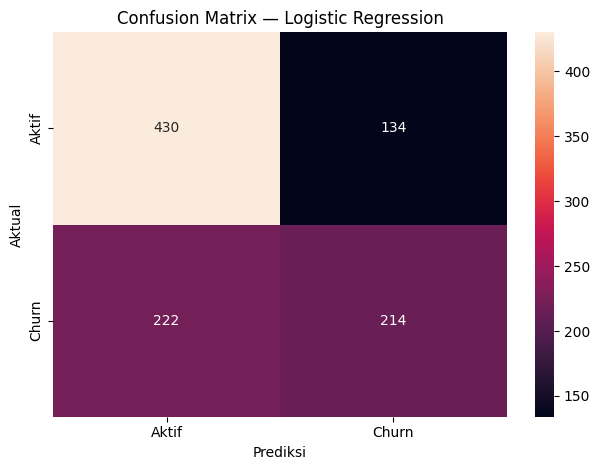

In [14]:
cm = confusion_matrix(y_test, prediksi, labels=["Aktif", "Churn"])
sns.heatmap(cm, annot=True, fmt="d", xticklabels=["Aktif", "Churn"], yticklabels=["Aktif", "Churn"])
plt.title("Confusion Matrix — Logistic Regression")
plt.xlabel("Prediksi")
plt.ylabel("Aktual")
plt.tight_layout()
plt.show()

### Interpretasi dan batasan model

Model Logistic Regression digunakan sebagai baseline, bukan sebagai model final yang pasti terbaik. Nilai evaluasi berasal dari pembagian train-test dengan random state tetap. Untuk penggunaan nyata, evaluasi dapat dilanjutkan dengan cross-validation, penyesuaian threshold, dan pemeriksaan precision-recall karena salah mengidentifikasi pelanggan berisiko dapat berdampak pada biaya retensi.

## 8. Kesimpulan

Dataset berhasil diaudit dan dibersihkan melalui kode yang dapat diulang. Missing value ditangani, nilai ekstrem numerik di-clip dengan IQR per status pelanggan, dan tipe data diperbaiki. Analisis awal menunjukkan kontrak bulanan dan jumlah komplain tinggi berkaitan dengan tingkat churn yang lebih tinggi. Jalur pemodelan menggunakan split terstratifikasi serta `ColumnTransformer` di dalam pipeline sehingga imputasi, scaling, dan encoding dipelajari dari data train saja.